In [3]:
# Predicting Students' Final Grades
#ITS836 Data Science in Big Data Analytics – Course Project

#Goal: predict the final grade (G3) at three points in the school year and see how early we can identify students who might struggle.

#Data: UCI Student Performance dataset (Cortez, 2008) – student-mat.csv and student-por.csv

# importing the libraries I need for this project
# pandas and numpy for working with the data, matplotlib and seaborn for the charts
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

Matplotlib is building the font cache; this may take a moment.


In [4]:
# loading both datasets - math course and portuguese course
# these files are separated by ; instead of , so I have to set sep=";"
mat = pd.read_csv("student-mat.csv", sep=";")
por = pd.read_csv("student-por.csv", sep=";")

# checking how many rows and columns each one has
print("Math:", mat.shape)
print("Portuguese:", por.shape)

# quick look at the first few rows of the math data
mat.head()

Math: (395, 33)
Portuguese: (649, 33)


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,6,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,4,5,5,6
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,10,7,8,10
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,2,15,14,15
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,4,6,10,10


In [5]:
# checking the column types to see which ones are numbers and which are text
mat.info()

# making sure there are no missing values before we start
print("\nMissing values in math:", mat.isna().sum().sum())
print("Missing values in portuguese:", por.isna().sum().sum())

<class 'pandas.DataFrame'>
RangeIndex: 395 entries, 0 to 394
Data columns (total 33 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   school      395 non-null    str  
 1   sex         395 non-null    str  
 2   age         395 non-null    int64
 3   address     395 non-null    str  
 4   famsize     395 non-null    str  
 5   Pstatus     395 non-null    str  
 6   Medu        395 non-null    int64
 7   Fedu        395 non-null    int64
 8   Mjob        395 non-null    str  
 9   Fjob        395 non-null    str  
 10  reason      395 non-null    str  
 11  guardian    395 non-null    str  
 12  traveltime  395 non-null    int64
 13  studytime   395 non-null    int64
 14  failures    395 non-null    int64
 15  schoolsup   395 non-null    str  
 16  famsup      395 non-null    str  
 17  paid        395 non-null    str  
 18  activities  395 non-null    str  
 19  nursery     395 non-null    str  
 20  higher      395 non-null    str  
 21  inte

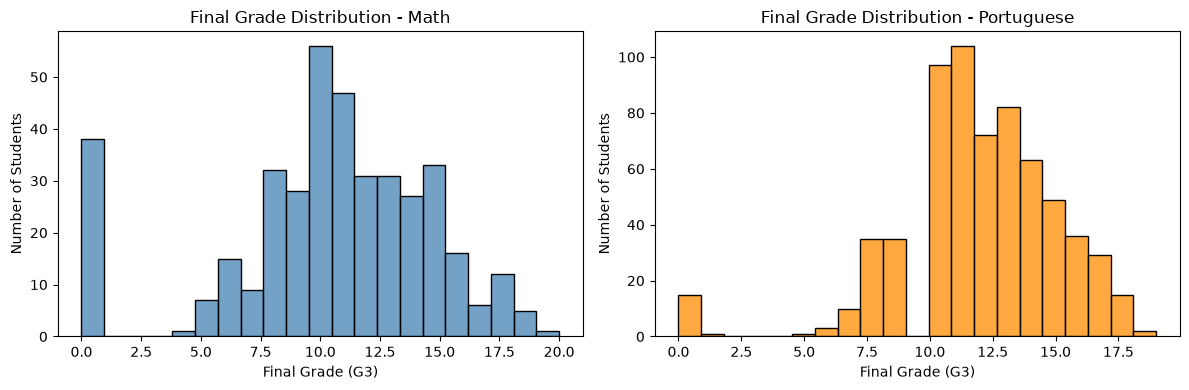

In [6]:
# looking at how the final grades (G3) are spread out in both courses
# grades go from 0 to 20, and 10 is the passing mark
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.histplot(mat["G3"], bins=21, ax=axes[0], color="steelblue")
axes[0].set_title("Final Grade Distribution - Math")
axes[0].set_xlabel("Final Grade (G3)")
axes[0].set_ylabel("Number of Students")

sns.histplot(por["G3"], bins=21, ax=axes[1], color="darkorange")
axes[1].set_title("Final Grade Distribution - Portuguese")
axes[1].set_xlabel("Final Grade (G3)")
axes[1].set_ylabel("Number of Students")

plt.tight_layout()
plt.show()

In [7]:
# basic stats for G3 so I can see the average and the range
print("Math G3:")
print(mat["G3"].describe().round(2))
print("\nPortuguese G3:")
print(por["G3"].describe().round(2))

# counting how many students got a 0 on the final grade
# these are most likely students who didn't take the final exam
print("\nStudents with G3 = 0 in math:", (mat["G3"] == 0).sum())
print("Students with G3 = 0 in portuguese:", (por["G3"] == 0).sum())

# checking how many students passed (10 or higher)
print("\nPass rate in math:", round((mat["G3"] >= 10).mean() * 100, 1), "%")
print("Pass rate in portuguese:", round((por["G3"] >= 10).mean() * 100, 1), "%")

Math G3:
count    395.00
mean      10.42
std        4.58
min        0.00
25%        8.00
50%       11.00
75%       14.00
max       20.00
Name: G3, dtype: float64

Portuguese G3:
count    649.00
mean      11.91
std        3.23
min        0.00
25%       10.00
50%       12.00
75%       14.00
max       19.00
Name: G3, dtype: float64

Students with G3 = 0 in math: 38
Students with G3 = 0 in portuguese: 15

Pass rate in math: 67.1 %
Pass rate in portuguese: 84.6 %


In [8]:
# looking at the earlier grades of students who got 0 at the end
# if their G1 was normal, the 0 probably means they didn't take the final, not that they failed
zeros_mat = mat[mat["G3"] == 0]
zeros_por = por[por["G3"] == 0]

print("Math students with G3 = 0, their average G1:", round(zeros_mat["G1"].mean(), 2))
print("Math students with G3 = 0 who also had G2 = 0:", (zeros_mat["G2"] == 0).sum(), "out of", len(zeros_mat))

print("\nPortuguese students with G3 = 0, their average G1:", round(zeros_por["G1"].mean(), 2))
print("Portuguese students with G3 = 0 who also had G2 = 0:", (zeros_por["G2"] == 0).sum(), "out of", len(zeros_por))

Math students with G3 = 0, their average G1: 7.53
Math students with G3 = 0 who also had G2 = 0: 13 out of 38

Portuguese students with G3 = 0, their average G1: 7.07
Portuguese students with G3 = 0 who also had G2 = 0: 7 out of 15


In [10]:
## Removing Students with a Final Grade of 0

#Students with G3 = 0 had an average G1 of around 7, so they were attending and getting grades early in the year. Some already had G2 = 0, which means they stopped partway through. These zeros most likely mean the student dropped out or didn't take the final exam, not that they actually scored zero.

#Since this project is about predicting grades and not predicting dropout, I'm removing these students from the analysis.

In [11]:
# removing the students who got 0 on the final grade
# keeping a copy of the original counts so I can report how many were removed
mat_before = len(mat)
por_before = len(por)

mat = mat[mat["G3"] > 0].reset_index(drop=True)
por = por[por["G3"] > 0].reset_index(drop=True)

print("Math: removed", mat_before - len(mat), "students, now", len(mat), "left")
print("Portuguese: removed", por_before - len(por), "students, now", len(por), "left")

Math: removed 38 students, now 357 left
Portuguese: removed 15 students, now 634 left


In [12]:
## Which Factors Are Related to the Final Grade?

#Using correlation to see how strongly each number column moves with G3. A value close to +1 or -1 means a strong relationship, and close to 0 means almost none. The main thing I want to see is which background factors matter most, since those are all I'll have at Stage 0.

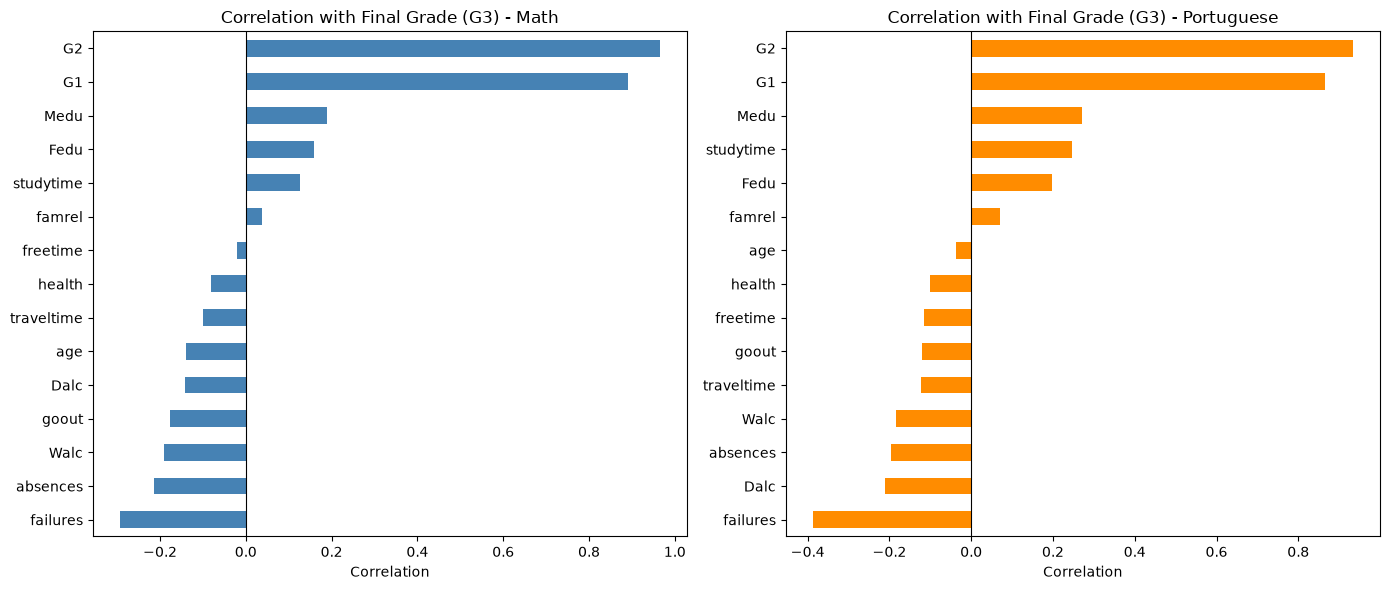

In [13]:
# calculating the correlation of every number column with G3
# select_dtypes picks only the number columns, since correlation doesn't work on text
mat_corr = mat.select_dtypes(include="number").corr()["G3"].drop("G3").sort_values()
por_corr = por.select_dtypes(include="number").corr()["G3"].drop("G3").sort_values()

# plotting them side by side so I can compare math and portuguese
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

mat_corr.plot(kind="barh", ax=axes[0], color="steelblue")
axes[0].set_title("Correlation with Final Grade (G3) - Math")
axes[0].set_xlabel("Correlation")
axes[0].axvline(0, color="black", linewidth=0.8)

por_corr.plot(kind="barh", ax=axes[1], color="darkorange")
axes[1].set_title("Correlation with Final Grade (G3) - Portuguese")
axes[1].set_xlabel("Correlation")
axes[1].axvline(0, color="black", linewidth=0.8)

plt.tight_layout()
plt.show()

In [14]:
# printing the top background factors without G1 and G2
# these are the ones that matter for Stage 0, before any grades come in
print("Math - strongest background factors:")
print(mat_corr.drop(["G1", "G2"]).abs().sort_values(ascending=False).head(5).round(3))

print("\nPortuguese - strongest background factors:")
print(por_corr.drop(["G1", "G2"]).abs().sort_values(ascending=False).head(5).round(3))

Math - strongest background factors:
failures    0.294
absences    0.213
Medu        0.190
Walc        0.190
goout       0.177
Name: G3, dtype: float64

Portuguese - strongest background factors:
failures     0.388
Medu         0.272
studytime    0.246
Dalc         0.211
Fedu         0.197
Name: G3, dtype: float64


In [15]:
## Converting Text Columns to Numbers

#17 columns are text (like yes/no or job types), and machine learning models need numbers. I'm using one-hot encoding with pd.get_dummies, which turns each text option into a 0/1 column. drop_first=True removes one option per column to avoid repeating the same information.

In [16]:
# finding which columns are text so I know what needs converting
text_cols = mat.select_dtypes(exclude="number").columns.tolist()
print("Text columns:", text_cols)
print("Number of text columns:", len(text_cols))

# converting the text columns into 0/1 columns
# drop_first=True leaves out one option per column, since it can be figured out from the others
mat_encoded = pd.get_dummies(mat, columns=text_cols, drop_first=True, dtype=int)
por_encoded = pd.get_dummies(por, columns=text_cols, drop_first=True, dtype=int)

print("\nMath before:", mat.shape, " after:", mat_encoded.shape)
print("Portuguese before:", por.shape, " after:", por_encoded.shape)

# quick look to make sure everything is numbers now
mat_encoded.head()

Text columns: ['school', 'sex', 'address', 'famsize', 'Pstatus', 'Mjob', 'Fjob', 'reason', 'guardian', 'schoolsup', 'famsup', 'paid', 'activities', 'nursery', 'higher', 'internet', 'romantic']
Number of text columns: 17

Math before: (357, 33)  after: (357, 42)
Portuguese before: (634, 33)  after: (634, 42)


,age,Medu,Fedu,traveltime,studytime,failures,famrel,freetime,goout,Dalc,...,guardian_mother,guardian_other,schoolsup_yes,famsup_yes,paid_yes,activities_yes,nursery_yes,higher_yes,internet_yes,romantic_yes
0,18,4,4,2,2,0,4,3,4,1,...,1,0,1,0,0,0,1,1,0,0
1,17,1,1,1,2,0,5,3,3,1,...,0,0,0,1,0,0,0,1,1,0
2,15,1,1,1,2,3,4,3,2,2,...,1,0,1,0,1,0,1,1,1,0
3,15,4,2,1,3,0,3,2,2,1,...,1,0,0,1,1,1,1,1,1,1
4,16,3,3,1,2,0,4,3,2,1,...,0,0,0,1,1,0,1,1,0,0


In [17]:
## Setting Up the Three Stages

# Each stage uses different columns to predict G3:
# - Stage 0: background columns only (no grades)
# - Stage 1: background + G1
# - Stage 2: background + G1 + G2

# I'm splitting the students into 80% training and 20% testing. The models learn from the training set and get evaluated on the testing set, which they've never seen. The same split is used for all three stages so the comparison is fair. random_state=42 makes the split the same every time the code runs, so the results can be reproduced.

In [18]:
from sklearn.model_selection import train_test_split

# the background columns are everything except the three grades
background_cols = [c for c in mat_encoded.columns if c not in ["G1", "G2", "G3"]]

# defining which columns each stage is allowed to use
stages = {
    "Stage 0 (no grades)": background_cols,
    "Stage 1 (+ G1)": background_cols + ["G1"],
    "Stage 2 (+ G1, G2)": background_cols + ["G1", "G2"],
}

for name, cols in stages.items():
    print(name, "-", len(cols), "columns")

# splitting each dataset once into 80% train and 20% test
# random_state=42 means I get the same split every time I run this
mat_train, mat_test = train_test_split(mat_encoded, test_size=0.2, random_state=42)
por_train, por_test = train_test_split(por_encoded, test_size=0.2, random_state=42)

print("\nMath - train:", len(mat_train), " test:", len(mat_test))
print("Portuguese - train:", len(por_train), " test:", len(por_test))

Stage 0 (no grades) - 39 columns
Stage 1 (+ G1) - 40 columns
Stage 2 (+ G1, G2) - 41 columns

Math - train: 285  test: 72
Portuguese - train: 507  test: 127


In [19]:
## Training the Models

#For each stage I'm training three regression models:
#- Linear Regression – finds the best straight-line relationship between the columns and G3
#- Random Forest – averages the predictions of many decision trees
#- Gradient Boosting – builds trees one after another, each one correcting the errors of the last

#Each model is evaluated on the test set using:
#- R² – how much of the variation in final grades the model explains (closer to 1 is better)
#- MAE (Mean Absolute Error) – how many grade points off the predictions are on average (lower is better)

In [20]:
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import r2_score, mean_absolute_error

# the three models I want to compare
# random_state=42 keeps the tree models the same every run
models = {
    "Linear Regression": LinearRegression(),
    "Random Forest": RandomForestRegressor(n_estimators=300, random_state=42),
    "Gradient Boosting": GradientBoostingRegressor(random_state=42),
}

# both courses with their train and test sets
courses = {
    "Math": (mat_train, mat_test),
    "Portuguese": (por_train, por_test),
}

# going through every course, stage, and model, training it and saving the scores
results = []
for course, (train, test) in courses.items():
    for stage, cols in stages.items():
        for model_name, model in models.items():
            model.fit(train[cols], train["G3"])      # learning from the training students
            preds = model.predict(test[cols])        # predicting for the test students
            results.append({
                "Course": course,
                "Stage": stage,
                "Model": model_name,
                "R2": round(r2_score(test["G3"], preds), 3),
                "MAE": round(mean_absolute_error(test["G3"], preds), 2),
            })

results_df = pd.DataFrame(results)
results_df

,Course,Stage,Model,R2,MAE
0,Math,Stage 0 (no grades),Linear Regression,0.202,2.32
1,Math,Stage 0 (no grades),Random Forest,0.233,2.22
2,Math,Stage 0 (no grades),Gradient Boosting,0.127,2.31
3,Math,Stage 1 (+ G1),Linear Regression,0.708,1.34
4,Math,Stage 1 (+ G1),Random Forest,0.766,1.14
5,Math,Stage 1 (+ G1),Gradient Boosting,0.743,1.22
6,Math,"Stage 2 (+ G1, G2)",Linear Regression,0.916,0.67
7,Math,"Stage 2 (+ G1, G2)",Random Forest,0.928,0.60
8,Math,"Stage 2 (+ G1, G2)",Gradient Boosting,0.915,0.67
9,Portuguese,Stage 0 (no grades),Linear Regression,0.221,2.02


In [21]:
## Comparing Against a Baseline

#To check whether the Stage 0 models are actually useful, I'm comparing them to a simple baseline that predicts the class average for every student. If Stage 0 has a lower error than the baseline, it means background information helps predict final grades even before any grades exist.

In [22]:
# baseline: predicting the training set average for every test student
# this is what you'd get with no model at all
for course, (train, test) in courses.items():
    baseline_preds = [train["G3"].mean()] * len(test)
    baseline_mae = mean_absolute_error(test["G3"], baseline_preds)

    # best Stage 0 result for this course
    stage0 = results_df[(results_df["Course"] == course) & (results_df["Stage"] == "Stage 0 (no grades)")]
    best_stage0_mae = stage0["MAE"].min()

    improvement = (baseline_mae - best_stage0_mae) / baseline_mae * 100
    print(f"{course}: baseline MAE = {baseline_mae:.2f}, best Stage 0 MAE = {best_stage0_mae:.2f}, "
          f"improvement = {improvement:.1f}%")

Math: baseline MAE = 2.57, best Stage 0 MAE = 2.22, improvement = 13.7%
Portuguese: baseline MAE = 2.42, best Stage 0 MAE = 1.88, improvement = 22.3%


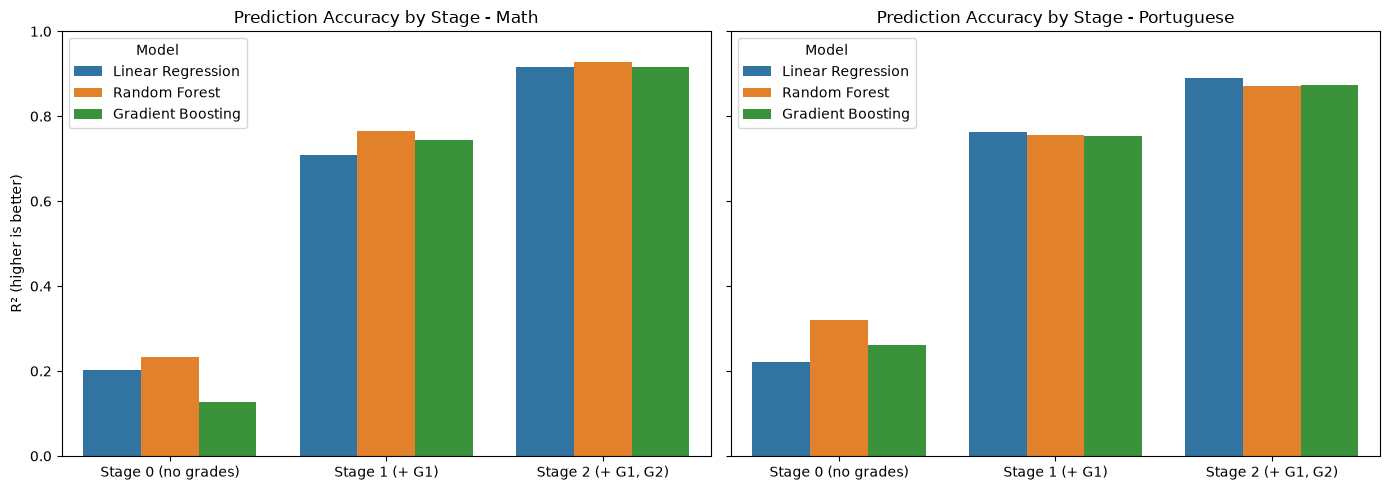

In [23]:
# charting R2 for every stage and model so the jump between stages is easy to see
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)

for ax, course in zip(axes, ["Math", "Portuguese"]):
    data = results_df[results_df["Course"] == course]
    sns.barplot(data=data, x="Stage", y="R2", hue="Model", ax=ax)
    ax.set_title(f"Prediction Accuracy by Stage - {course}")
    ax.set_xlabel("")
    ax.set_ylabel("R² (higher is better)")
    ax.set_ylim(0, 1)

plt.tight_layout()
plt.show()

In [25]:
## Which Background Factors Drive the Stage 0 Predictions?

# To see which factors the Stage 0 model relies on, I'm using permutation importance. It shuffles one column at a time and measures how much worse the predictions get. A big increase in error means the model depends heavily on that column. I'm using the Random Forest model since it had the best Stage 0 results for both courses.

Math - top 10 factors:
schoolsup_yes    0.115
failures         0.106
studytime        0.050
Fjob_teacher     0.033
sex_M            0.032
Walc             0.026
Mjob_health      0.020
paid_yes         0.015
age              0.015
freetime         0.013
dtype: float64 

Portuguese - top 10 factors:
failures         0.369
higher_yes       0.173
age              0.057
Medu             0.051
schoolsup_yes    0.036
school_MS        0.035
studytime        0.035
health           0.026
freetime         0.018
Walc             0.016
dtype: float64 



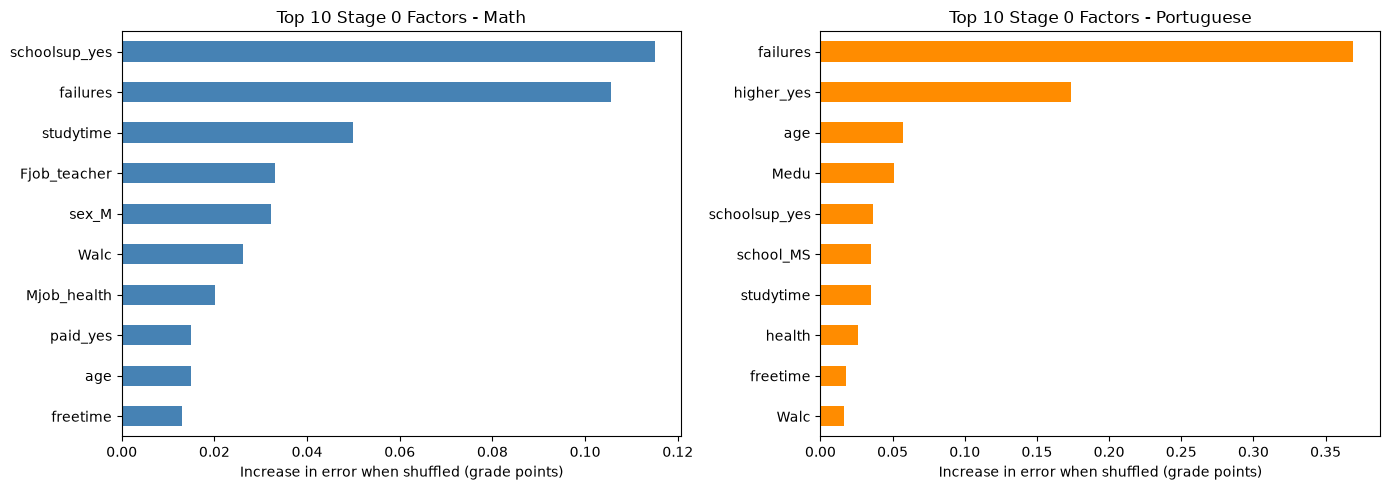

In [26]:
from sklearn.inspection import permutation_importance

stage0_cols = stages["Stage 0 (no grades)"]
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, (course, (train, test)) in zip(axes, courses.items()):
    # training the Stage 0 random forest again for this course
    rf = RandomForestRegressor(n_estimators=300, random_state=42)
    rf.fit(train[stage0_cols], train["G3"])

    # shuffling each column 20 times and measuring how much the error increases
    perm = permutation_importance(rf, test[stage0_cols], test["G3"],
                                  n_repeats=20, random_state=42,
                                  scoring="neg_mean_absolute_error")

    # keeping the top 10 most important factors
    importance = pd.Series(perm.importances_mean, index=stage0_cols).sort_values(ascending=False).head(10)
    print(f"{course} - top 10 factors:")
    print(importance.round(3), "\n")

    importance.sort_values().plot(kind="barh", ax=ax,
                                  color="steelblue" if course == "Math" else "darkorange")
    ax.set_title(f"Top 10 Stage 0 Factors - {course}")
    ax.set_xlabel("Increase in error when shuffled (grade points)")

plt.tight_layout()
plt.show()

In [27]:
## What Drives the Stage 0 Predictions

# - Past failures is a top factor in both courses, and by far the strongest in Portuguese.
# - In math, students already receiving extra school support (schoolsup) tend to score lower. This is likely because the school gave them support after noticing they were struggling, so it acts as an existing warning flag.
# - In Portuguese, wanting to pursue higher education (higher) is the second strongest factor, which points to motivation.
# - Study time matters in both courses.
# - Most factors are individually small, so the Stage 0 prediction comes from many weak signals combined rather than one strong one.

At-risk students in math test set: 19 out of 72
At-risk students in portuguese test set: 22 out of 127


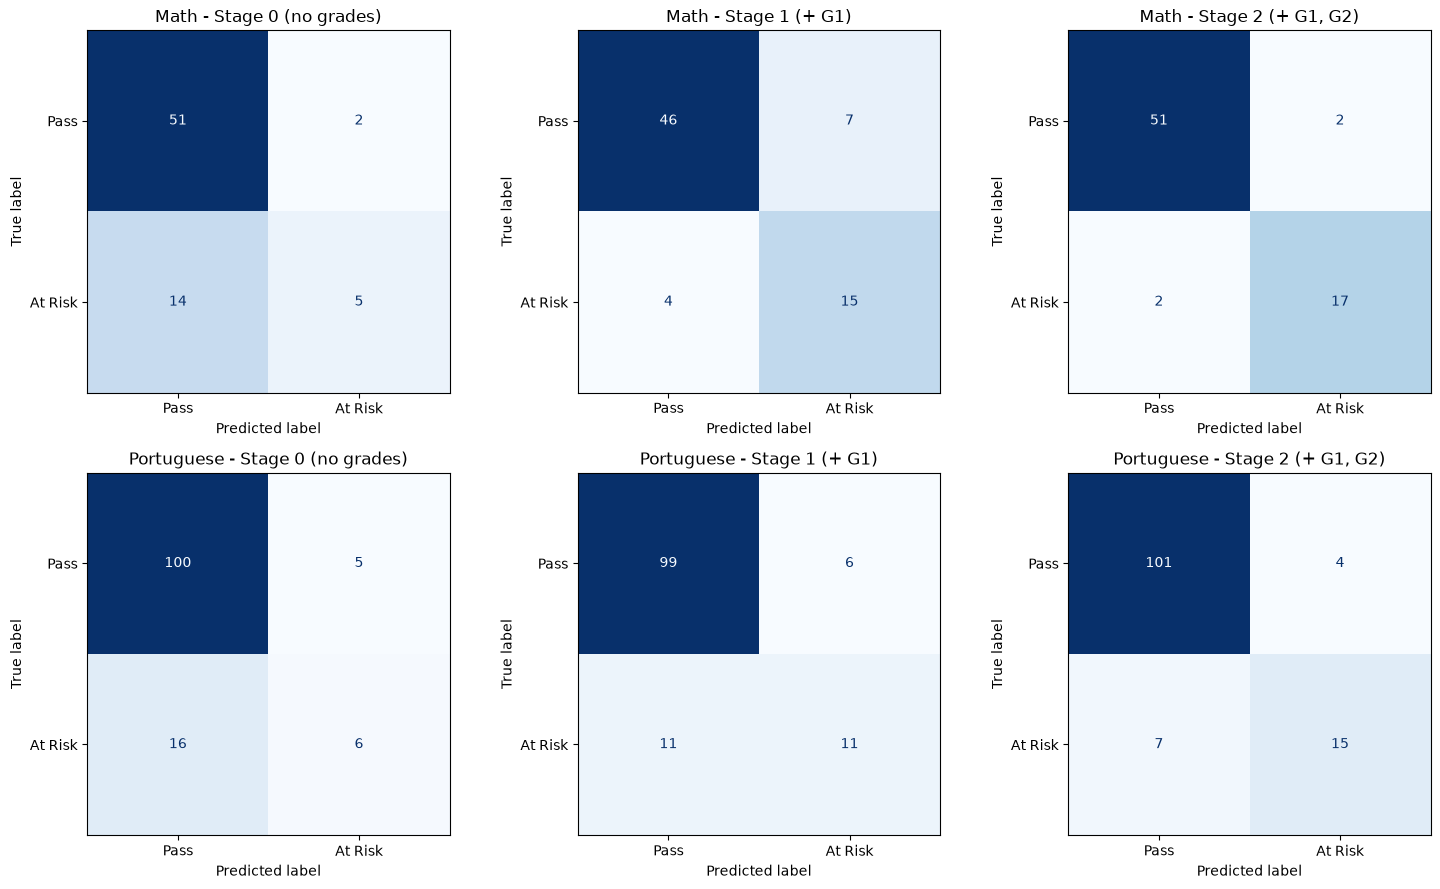

,Course,Stage,Accuracy,Recall (at-risk caught)
0,Math,Stage 0 (no grades),0.778,0.263
1,Math,Stage 1 (+ G1),0.847,0.789
2,Math,"Stage 2 (+ G1, G2)",0.944,0.895
3,Portuguese,Stage 0 (no grades),0.835,0.273
4,Portuguese,Stage 1 (+ G1),0.866,0.500
5,Portuguese,"Stage 2 (+ G1, G2)",0.913,0.682


In [28]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import confusion_matrix, accuracy_score, recall_score, ConfusionMatrixDisplay

# labeling students as at risk (1) if their final grade is below 10, otherwise pass (0)
for df in [mat_train, mat_test, por_train, por_test]:
    df["at_risk"] = (df["G3"] < 10).astype(int)

print("At-risk students in math test set:", mat_test["at_risk"].sum(), "out of", len(mat_test))
print("At-risk students in portuguese test set:", por_test["at_risk"].sum(), "out of", len(por_test))

# training a classifier for every course and stage, and drawing a confusion matrix for each
fig, axes = plt.subplots(2, 3, figsize=(15, 9))
class_results = []

for row, (course, (train, test)) in enumerate(courses.items()):
    for col, (stage, cols) in enumerate(stages.items()):
        clf = RandomForestClassifier(n_estimators=300, random_state=42, class_weight="balanced")
        clf.fit(train[cols], train["at_risk"])
        preds = clf.predict(test[cols])

        class_results.append({
            "Course": course,
            "Stage": stage,
            "Accuracy": round(accuracy_score(test["at_risk"], preds), 3),
            "Recall (at-risk caught)": round(recall_score(test["at_risk"], preds), 3),
        })

        ConfusionMatrixDisplay(confusion_matrix(test["at_risk"], preds),
                               display_labels=["Pass", "At Risk"]).plot(ax=axes[row, col], colorbar=False, cmap="Blues")
        axes[row, col].set_title(f"{course} - {stage}")

plt.tight_layout()
plt.show()

pd.DataFrame(class_results)

In [ ]:
## What the Pass/Fail Results Show

#- At Stage 0, the model catches only about 26–27% of at-risk students (5 of 19 in math, 6 of 22 in Portuguese). Accuracy looks high, but only because most students pass.
#- Adding G1 makes a big difference, especially in math, where recall jumps from 26% to 79%.
#- By Stage 2, the model catches 90% of at-risk students in math and 68% in Portuguese.
#- Background information alone beats guessing the class average, but it isn't reliable enough to flag at-risk students on its own. The first-period grade is the point where early warning becomes practical.